# Plant Disease Detection with Deep Learning
**Problem:** classify leaf images into healthy / diseased classes (PlantVillage).
**Models:** (A) baseline CNN trained from scratch, (B) EfficientNetB0 transfer learning (frozen head, then fine-tuning).
**Extras:** Grad-CAM explainability, field-image test, error analysis, limitations.

**Before running:** Runtime > Change runtime type > GPU.

## 1. Setup

In [1]:
!pip install -q kagglehub

In [2]:
import os, random, pathlib, hashlib
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score
from sklearn.utils.class_weight import compute_class_weight

SEED = 42
random.seed(SEED); np.random.seed(SEED); tf.random.set_seed(SEED)

IMG_SIZE = 224
BATCH = 32
AUTOTUNE = tf.data.AUTOTUNE

# Use None for all 38 classes, or a list of crops to keep training fast, e.g. ["Tomato", "Potato", "Apple"]
SUBSET_CROPS = None

EPOCHS_BASELINE = 15
EPOCHS_PHASE1 = 8
EPOCHS_PHASE2 = 10

print("TensorFlow", tf.__version__)
print("GPU:", tf.config.list_physical_devices("GPU"))

TensorFlow 2.21.0
GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


## 2. Download data and audit it

In [3]:
import kagglehub
root = pathlib.Path(kagglehub.dataset_download("abdallahalidev/plantvillage-dataset"))
candidates = [p for p in root.rglob("color") if p.is_dir()]
assert candidates, "Could not find the 'color' folder, inspect the download path: " + str(root)
DATA_DIR = candidates[0]
print("Using:", DATA_DIR)

Using Colab cache for faster access to the 'plantvillage-dataset' dataset.
Using: /kaggle/input/plantvillage-dataset/plantvillage dataset/color


In [4]:
paths, labels = [], []
for cls_dir in sorted(DATA_DIR.iterdir()):
    if not cls_dir.is_dir():
        continue
    if SUBSET_CROPS and cls_dir.name.split("___")[0] not in SUBSET_CROPS:
        continue
    for f in cls_dir.iterdir():
        if f.suffix.lower() in (".jpg", ".jpeg", ".png"):
            paths.append(str(f)); labels.append(cls_dir.name)

df = pd.DataFrame({"path": paths, "label": labels})
print("Images:", len(df), "| Classes:", df.label.nunique())

Images: 54305 | Classes: 38


In [5]:
# Exact-duplicate check (duplicates across splits cause leakage and inflated scores)
def file_hash(p):
    with open(p, "rb") as f:
        return hashlib.md5(f.read()).hexdigest()

df["hash"] = df.path.map(file_hash)
n_dup = df.duplicated("hash").sum()
df = df.drop_duplicates("hash").reset_index(drop=True)
print("Exact duplicates removed:", n_dup, "| Remaining:", len(df))

# Corrupt-file check on a random sample
bad = []
for p in df.sample(min(500, len(df)), random_state=SEED).path:
    try:
        tf.io.decode_image(tf.io.read_file(p), channels=3, expand_animations=False)
    except Exception:
        bad.append(p)
print("Corrupt files in sample:", len(bad))

Exact duplicates removed: 21 | Remaining: 54284
Corrupt files in sample: 0


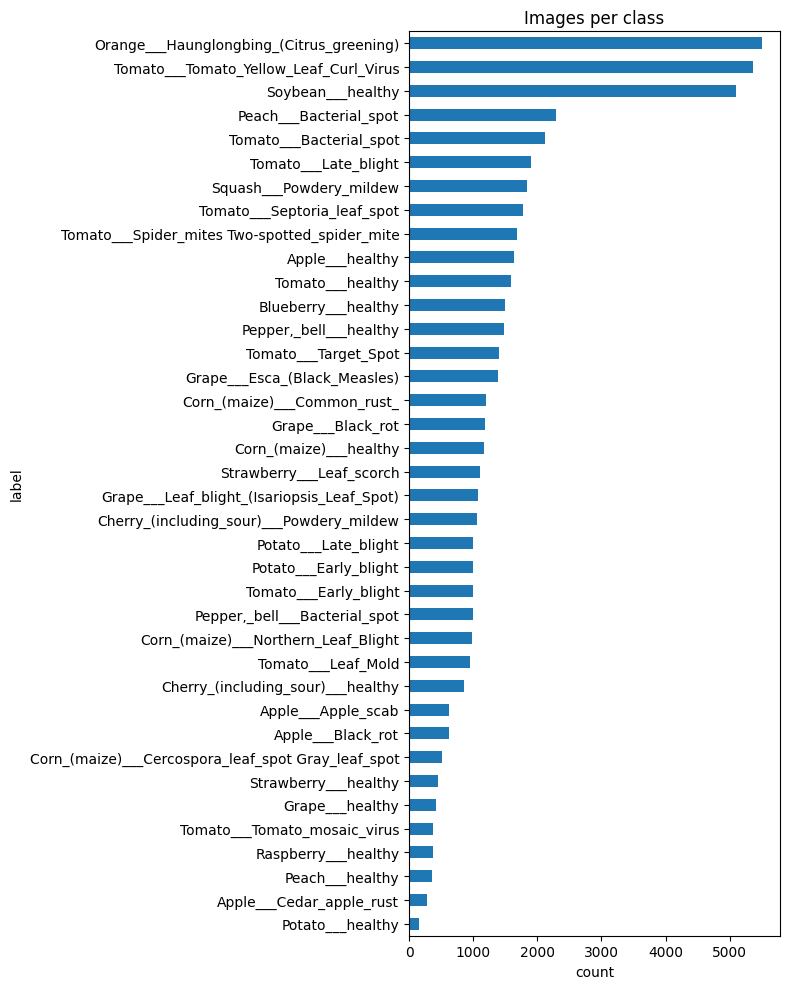

Imbalance ratio (max/min): 36.2


In [6]:
counts = df.label.value_counts().sort_values()
plt.figure(figsize=(8, 10))
counts.plot(kind="barh")
plt.title("Images per class"); plt.xlabel("count"); plt.tight_layout(); plt.show()
print("Imbalance ratio (max/min):", round(counts.max() / counts.min(), 1))

## 3. Stratified split (70 / 15 / 15), done before any augmentation

In [7]:
class_names = sorted(df.label.unique())
class_to_idx = {c: i for i, c in enumerate(class_names)}
NUM_CLASSES = len(class_names)
y_all = df.label.map(class_to_idx).values.astype("int32")
X_all = df.path.values

X_train, X_tmp, y_train, y_tmp = train_test_split(X_all, y_all, test_size=0.30, stratify=y_all, random_state=SEED)
X_val, X_test, y_val, y_test = train_test_split(X_tmp, y_tmp, test_size=0.50, stratify=y_tmp, random_state=SEED)
print("Train:", len(X_train), "Val:", len(X_val), "Test:", len(X_test))

Train: 37998 Val: 8143 Test: 8143


In [8]:
def load_image(path, label):
    img = tf.io.read_file(path)
    img = tf.io.decode_image(img, channels=3, expand_animations=False)
    img.set_shape([None, None, 3])
    img = tf.image.resize(img, (IMG_SIZE, IMG_SIZE))   # float32, range 0-255
    return img, label

def make_ds(X, y, training=False):
    ds = tf.data.Dataset.from_tensor_slices((X, y))
    if training:
        ds = ds.shuffle(len(X), seed=SEED, reshuffle_each_iteration=True)
    return ds.map(load_image, num_parallel_calls=AUTOTUNE).batch(BATCH).prefetch(AUTOTUNE)

train_ds = make_ds(X_train, y_train, training=True)
val_ds = make_ds(X_val, y_val)
test_ds = make_ds(X_test, y_test)   # not shuffled, so prediction order matches y_test

## 4. Augmentation (training only, built into the model so it is inactive at inference)

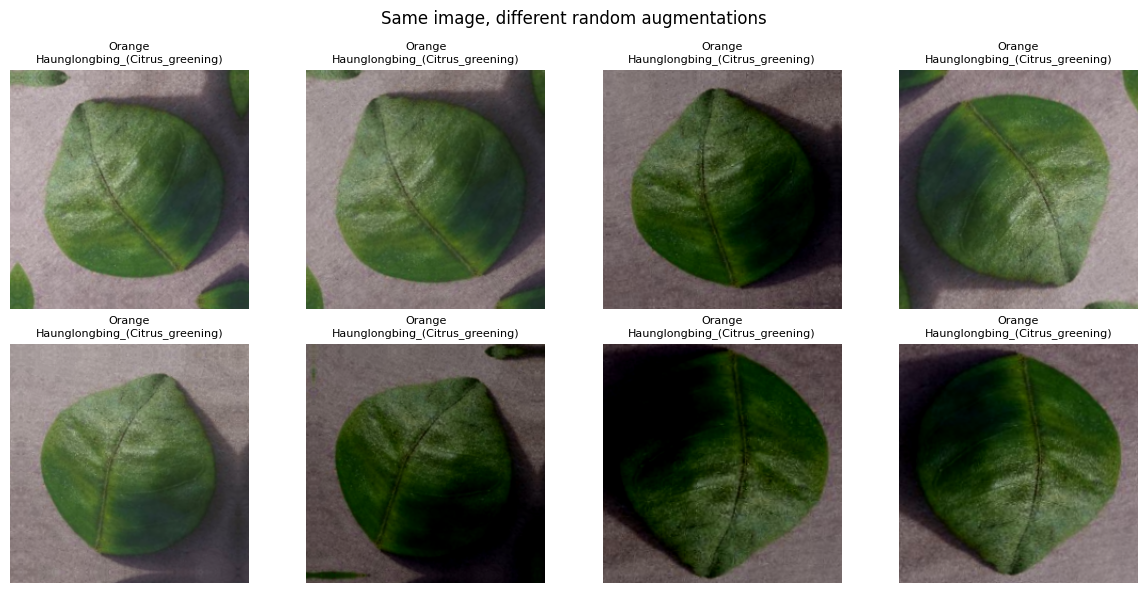

In [9]:
augment = keras.Sequential([
    layers.RandomFlip("horizontal_and_vertical"),
    layers.RandomRotation(0.1),
    layers.RandomZoom(0.1),
    layers.RandomBrightness(0.2, value_range=(0, 255)),
    layers.RandomContrast(0.2),
], name="augmentation")

imgs, lbls = next(iter(train_ds))
plt.figure(figsize=(12, 6))
for i in range(8):
    plt.subplot(2, 4, i + 1)
    out = augment(imgs[:1], training=True)[0]
    plt.imshow(tf.clip_by_value(out, 0, 255).numpy().astype("uint8"))
    plt.title(class_names[int(lbls[0])].replace("___", "\n"), fontsize=8); plt.axis("off")
plt.suptitle("Same image, different random augmentations"); plt.tight_layout(); plt.show()

## 5. Shared training utilities

In [10]:
cw = compute_class_weight("balanced", classes=np.arange(NUM_CLASSES), y=y_train)
class_weights = {i: float(w) for i, w in enumerate(cw)}

def get_callbacks(name):
    return [
        keras.callbacks.EarlyStopping(monitor="val_loss", patience=4, restore_best_weights=True),
        keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.3, patience=2, min_lr=1e-7, verbose=1),
        keras.callbacks.ModelCheckpoint(f"{name}.keras", monitor="val_loss", save_best_only=True),
    ]

def plot_history(histories, title):
    acc, val_acc, loss, val_loss = [], [], [], []
    for h in histories:
        acc += h.history["accuracy"]; val_acc += h.history["val_accuracy"]
        loss += h.history["loss"]; val_loss += h.history["val_loss"]
    fig, ax = plt.subplots(1, 2, figsize=(12, 4))
    ax[0].plot(acc, label="train"); ax[0].plot(val_acc, label="val"); ax[0].set_title(title + " accuracy"); ax[0].legend()
    ax[1].plot(loss, label="train"); ax[1].plot(val_loss, label="val"); ax[1].set_title(title + " loss"); ax[1].legend()
    for a in ax: a.set_xlabel("epoch")
    plt.tight_layout(); plt.show()

## 6. Model A: baseline CNN (from scratch)

In [11]:
def build_baseline():
    inp = keras.Input((IMG_SIZE, IMG_SIZE, 3))
    x = augment(inp)
    x = layers.Rescaling(1.0 / 255)(x)
    for f in [32, 64, 128, 256]:
        x = layers.Conv2D(f, 3, padding="same", use_bias=False)(x)
        x = layers.BatchNormalization()(x)
        x = layers.ReLU()(x)
        x = layers.MaxPooling2D()(x)
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dropout(0.4)(x)
    out = layers.Dense(NUM_CLASSES, activation="softmax")(x)
    return keras.Model(inp, out, name="baseline_cnn")

baseline = build_baseline()
baseline.compile(optimizer=keras.optimizers.Adam(1e-3),
                 loss="sparse_categorical_crossentropy", metrics=["accuracy"])
baseline.summary()

Model: "baseline_cnn"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ augmentation (Sequential)       │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling (Rescaling)           │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 224, 224, 32)   │           864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 224, 224, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu (ReLU)                    │ (None, 224, 224, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 112, 112, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 112, 112, 64)   │        18,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 112, 112, 64)   │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_1 (ReLU)                  │ (None, 112, 112, 64)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 56, 56, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 56, 56, 128)    │        73,728 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 56, 56, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_2 (ReLU)                  │ (None, 56, 56, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 28, 28, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 28, 28, 256)    │       294,912 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 28, 28, 256)    │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_3 (ReLU)                  │ (None, 28, 28, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 14, 14, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 256)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 38)             │         9,766 │
└─────────────────────────────────┴────────────────────────┴─────────────

 Total params: 399,622 (1.52 MB)

 Trainable params: 398,662 (1.52 MB)

 Non-trainable params: 960 (3.75 KB)

Epoch 1/15
1188/1188 ━━━━━━━━━━━━━━━━━━━━ 165s 132ms/step - accuracy: 0.4655 - loss: 1.8584 - val_accuracy: 0.4862 - val_loss: 2.0679 - learning_rate: 0.0010
Epoch 2/15
1188/1188 ━━━━━━━━━━━━━━━━━━━━ 157s 132ms/step - accuracy: 0.6771 - loss: 1.0400 - val_accuracy: 0.6127 - val_loss: 1.2062 - learning_rate: 0.0010
Epoch 3/15
1188/1188 ━━━━━━━━━━━━━━━━━━━━ 157s 132ms/step - accuracy: 0.7556 - loss: 0.7558 - val_accuracy: 0.5116 - val_loss: 1.9338 - learning_rate: 0.0010
Epoch 4/15
1188/1188 ━━━━━━━━━━━━━━━━━━━━ 157s 132ms/step - accuracy: 0.7977 - loss: 0.6062 - val_accuracy: 0.7958 - val_loss: 0.6312 - learning_rate: 0.0010
Epoch 5/15
1188/1188 ━━━━━━━━━━━━━━━━━━━━ 158s 133ms/step - accuracy: 0.8334 - loss: 0.4961 - val_accuracy: 0.8432 - val_loss: 0.4883 - learning_rate: 0.0010
Epoch 6/15
1188/1188 ━━━━━━━━━━━━━━━━━━━━ 156s 132ms/step - accuracy: 0.8447 - loss: 0.4518 - val_accuracy: 0.8687 - val_loss: 0.3993 - learning_rate: 0.0010
Epoch 7/15
1188/1188 ━━━━━━━━━━━━━━━━━━━━ 157s 132ms

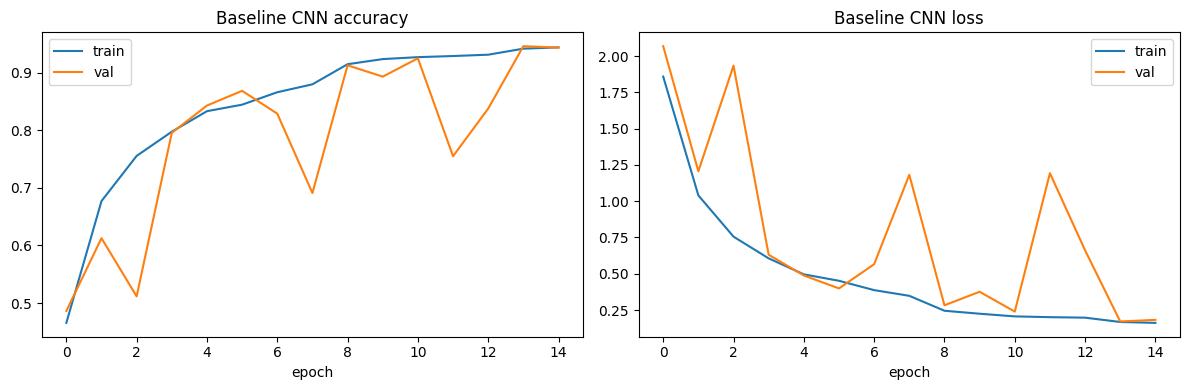

In [12]:
hist_base = baseline.fit(train_ds, validation_data=val_ds, epochs=EPOCHS_BASELINE,
                         class_weight=class_weights, callbacks=get_callbacks("baseline_cnn"))
plot_history([hist_base], "Baseline CNN")

## 7. Model B: EfficientNetB0 transfer learning
**Why transfer learning:** ImageNet features (edges, textures, shapes) transfer well to leaf lesions, so we need less data and time and usually get better accuracy than training from scratch.
**Phase 1:** freeze the backbone, train only the new head. **Phase 2:** unfreeze the top layers and fine-tune with a very low learning rate. BatchNorm layers stay frozen for stability.

In [14]:
def build_effnet():
    base = keras.applications.EfficientNetB0(include_top=False, weights="imagenet",
                                             input_shape=(IMG_SIZE, IMG_SIZE, 3))
    base.trainable = False
    inp = keras.Input((IMG_SIZE, IMG_SIZE, 3))
    x = augment(inp)
    x = base(x, training=False)          # EfficientNet has its own input scaling (expects 0-255)
    x = layers.GlobalAveragePooling2D(name="gap")(x)
    x = layers.Dropout(0.3, name="head_dropout")(x)
    out = layers.Dense(NUM_CLASSES, activation="softmax", name="predictions")(x)
    return keras.Model(inp, out, name="effnetb0"), base

effnet, base = build_effnet()
effnet.compile(optimizer=keras.optimizers.Adam(1e-3),
               loss="sparse_categorical_crossentropy", metrics=["accuracy"])
hist_p1 = effnet.fit(train_ds, validation_data=val_ds, epochs=EPOCHS_PHASE1,
                     class_weight=class_weights, callbacks=get_callbacks("effnet_phase1"))

Epoch 1/8
1188/1188 ━━━━━━━━━━━━━━━━━━━━ 123s 95ms/step - accuracy: 0.8119 - loss: 0.8791 - val_accuracy: 0.9145 - val_loss: 0.3360 - learning_rate: 0.0010
Epoch 2/8
1188/1188 ━━━━━━━━━━━━━━━━━━━━ 113s 95ms/step - accuracy: 0.9032 - loss: 0.3602 - val_accuracy: 0.9350 - val_loss: 0.2433 - learning_rate: 0.0010
Epoch 3/8
1188/1188 ━━━━━━━━━━━━━━━━━━━━ 111s 93ms/step - accuracy: 0.9170 - loss: 0.2877 - val_accuracy: 0.9482 - val_loss: 0.1905 - learning_rate: 0.0010
Epoch 4/8
1188/1188 ━━━━━━━━━━━━━━━━━━━━ 114s 96ms/step - accuracy: 0.9247 - loss: 0.2478 - val_accuracy: 0.9462 - val_loss: 0.1793 - learning_rate: 0.0010
Epoch 5/8
1188/1188 ━━━━━━━━━━━━━━━━━━━━ 110s 93ms/step - accuracy: 0.9296 - loss: 0.2241 - val_accuracy: 0.9429 - val_loss: 0.1725 - learning_rate: 0.0010
Epoch 6/8
1188/1188 ━━━━━━━━━━━━━━━━━━━━ 111s 93ms/step - accuracy: 0.9338 - loss: 0.2089 - val_accuracy: 0.9493 - val_loss: 0.1640 - learning_rate: 0.0010
Epoch 7/8
1188/1188 ━━━━━━━━━━━━━━━━━━━━ 113s 95ms/step - accura

In [ ]:
# Phase 2: fine-tune the top 30 layers at a low learning rate (BatchNorm stays frozen)
base.trainable = True
for layer in base.layers[:-30]:
    layer.trainable = False
for layer in base.layers:
    if isinstance(layer, layers.BatchNormalization):
        layer.trainable = False

effnet.compile(optimizer=keras.optimizers.Adam(1e-5),
               loss="sparse_categorical_crossentropy", metrics=["accuracy"])
hist_p2 = effnet.fit(train_ds, validation_data=val_ds, epochs=EPOCHS_PHASE2,
                     class_weight=class_weights, callbacks=get_callbacks("effnet_phase2"))
plot_history([hist_p1, hist_p2], "EfficientNetB0 (phase 1 + 2)")

Epoch 1/10
1188/1188 ━━━━━━━━━━━━━━━━━━━━ 132s 103ms/step - accuracy: 0.9467 - loss: 0.1635 - val_accuracy: 0.9643 - val_loss: 0.1092 - learning_rate: 1.0000e-05
Epoch 2/10
1188/1188 ━━━━━━━━━━━━━━━━━━━━ 120s 101ms/step - accuracy: 0.9535 - loss: 0.1418 - val_accuracy: 0.9681 - val_loss: 0.0989 - learning_rate: 1.0000e-05
Epoch 3/10
1188/1188 ━━━━━━━━━━━━━━━━━━━━ 120s 101ms/step - accuracy: 0.9553 - loss: 0.1308 - val_accuracy: 0.9704 - val_loss: 0.0930 - learning_rate: 1.0000e-05
Epoch 4/10
1188/1188 ━━━━━━━━━━━━━━━━━━━━ 121s 102ms/step - accuracy: 0.9613 - loss: 0.1143 - val_accuracy: 0.9686 - val_loss: 0.0967 - learning_rate: 1.0000e-05
Epoch 5/10
1188/1188 ━━━━━━━━━━━━━━━━━━━━ 119s 100ms/step - accuracy: 0.9636 - loss: 0.1106 - val_accuracy: 0.9747 - val_loss: 0.0805 - learning_rate: 1.0000e-05
Epoch 6/10
1188/1188 ━━━━━━━━━━━━━━━━━━━━ 120s 101ms/step - accuracy: 0.9636 - loss: 0.1071 - val_accuracy: 0.9758 - val_loss: 0.0759 - learning_rate: 1.0000e-05
Epoch 7/10
1188/1188 ━━━━━━━

## 8. Evaluation on the held-out test set (run once, after all decisions are final)

In [16]:
def evaluate(model, name):
    probs = model.predict(test_ds, verbose=0)
    pred = probs.argmax(1)
    acc = accuracy_score(y_test, pred)
    rep = classification_report(y_test, pred, target_names=class_names, output_dict=True, zero_division=0)
    return {"model": name, "accuracy": acc, "macro_f1": rep["macro avg"]["f1-score"],
            "weighted_f1": rep["weighted avg"]["f1-score"]}, probs, pred

res_base, probs_base, pred_base = evaluate(baseline, "Baseline CNN")
res_eff, probs_eff, pred_eff = evaluate(effnet, "EfficientNetB0 (fine-tuned)")
pd.DataFrame([res_base, res_eff]).round(4)

,model,accuracy,macro_f1,weighted_f1
0,Baseline CNN,0.9479,0.9422,0.9479
1,EfficientNetB0 (fine-tuned),0.9721,0.9638,0.9723


In [17]:
print(classification_report(y_test, pred_eff, target_names=class_names, digits=3, zero_division=0))

                                                    precision    recall  f1-score   support

                                Apple___Apple_scab      1.000     0.957     0.978        94
                                 Apple___Black_rot      0.989     0.989     0.989        93
                          Apple___Cedar_apple_rust      1.000     1.000     1.000        41
                                   Apple___healthy      0.984     0.996     0.990       245
                               Blueberry___healthy      0.996     1.000     0.998       226
          Cherry_(including_sour)___Powdery_mildew      1.000     0.994     0.997       158
                 Cherry_(including_sour)___healthy      0.992     0.992     0.992       128
Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot      0.913     0.818     0.863        77
                       Corn_(maize)___Common_rust_      1.000     1.000     1.000       179
               Corn_(maize)___Northern_Leaf_Blight      0.909     0.952     0.9

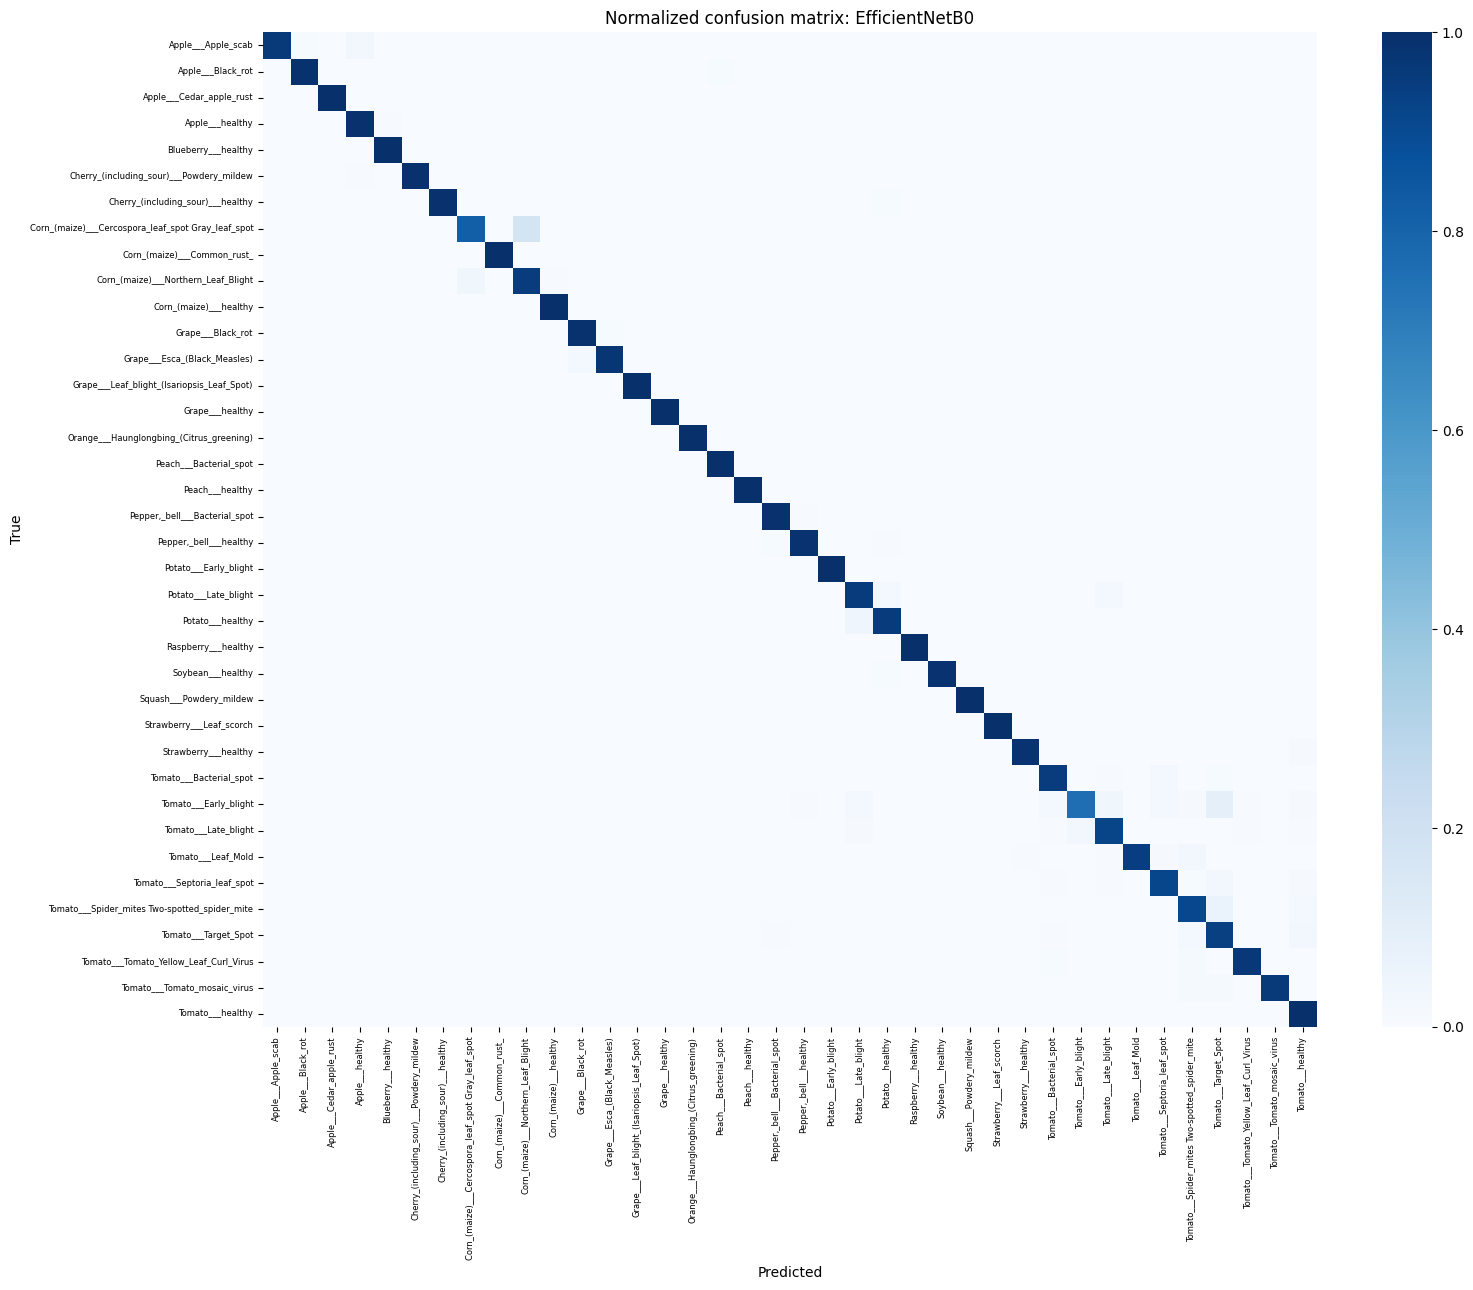

,count,true,predicted as
0,17,Tomato___Spider_mites Two-spotted_spider_mite,Tomato___Target_Spot
1,14,Tomato___Early_blight,Tomato___Target_Spot
2,14,Corn_(maize)___Cercospora_leaf_spot Gray_leaf_...,Corn_(maize)___Northern_Leaf_Blight
3,13,Tomato___Tomato_Yellow_Leaf_Curl_Virus,Tomato___Spider_mites Two-spotted_spider_mite
4,9,Tomato___Tomato_Yellow_Leaf_Curl_Virus,Tomato___Bacterial_spot
5,8,Tomato___Septoria_leaf_spot,Tomato___Target_Spot
6,8,Tomato___Late_blight,Tomato___Early_blight
7,7,Tomato___Bacterial_spot,Tomato___Septoria_leaf_spot
8,6,Tomato___Target_Spot,Tomato___healthy
9,6,Tomato___Early_blight,Tomato___Late_blight


In [18]:
cm = confusion_matrix(y_test, pred_eff, normalize="true")
plt.figure(figsize=(16, 13))
sns.heatmap(cm, cmap="Blues", xticklabels=class_names, yticklabels=class_names, cbar=True)
plt.title("Normalized confusion matrix: EfficientNetB0"); plt.xlabel("Predicted"); plt.ylabel("True")
plt.xticks(fontsize=6, rotation=90); plt.yticks(fontsize=6); plt.tight_layout(); plt.show()

# Most confused class pairs
cm_raw = confusion_matrix(y_test, pred_eff)
np.fill_diagonal(cm_raw, 0)
pairs = [(cm_raw[i, j], class_names[i], class_names[j]) for i in range(NUM_CLASSES) for j in range(NUM_CLASSES) if cm_raw[i, j] > 0]
pd.DataFrame(sorted(pairs, reverse=True)[:10], columns=["count", "true", "predicted as"])

## 9. Grad-CAM: what is the model looking at?

In [19]:
conv_model = keras.Model(base.input, base.get_layer("top_activation").output)
gap_l = effnet.get_layer("gap"); drop_l = effnet.get_layer("head_dropout"); pred_l = effnet.get_layer("predictions")

def read_img(path):
    img = tf.io.decode_image(tf.io.read_file(path), channels=3, expand_animations=False)
    return tf.image.resize(img, (IMG_SIZE, IMG_SIZE)).numpy()

def grad_cam(img):
    x = tf.convert_to_tensor(img[None, ...])
    with tf.GradientTape() as tape:
        conv_out = conv_model(x, training=False)
        tape.watch(conv_out)
        p = pred_l(drop_l(gap_l(conv_out), training=False))
        cls = tf.argmax(p[0])
        score = p[:, cls]
    grads = tape.gradient(score, conv_out)
    weights = tf.reduce_mean(grads, axis=(0, 1, 2))
    cam = tf.nn.relu(tf.reduce_sum(conv_out[0] * weights, axis=-1))
    cam = cam / (tf.reduce_max(cam) + 1e-8)
    cam = tf.image.resize(cam[..., None], (IMG_SIZE, IMG_SIZE))[..., 0].numpy()
    return cam, int(cls), float(p[0, cls])

def show_cams(indices, title):
    plt.figure(figsize=(3.2 * len(indices), 6.4))
    for k, i in enumerate(indices):
        img = read_img(X_test[i]); cam, cls, conf = grad_cam(img)
        plt.subplot(2, len(indices), k + 1); plt.imshow(img.astype("uint8")); plt.axis("off")
        plt.title("True: " + class_names[y_test[i]].replace("___", "\n"), fontsize=7)
        plt.subplot(2, len(indices), len(indices) + k + 1)
        plt.imshow(img.astype("uint8")); plt.imshow(cam, cmap="jet", alpha=0.45); plt.axis("off")
        plt.title("Pred: " + class_names[cls].replace("___", "\n") + f"\n{conf:.2f}", fontsize=7)
    plt.suptitle(title); plt.tight_layout(); plt.show()

rng = np.random.default_rng(SEED)
correct_idx = rng.choice(np.where(pred_eff == y_test)[0], 5, replace=False)
show_cams(correct_idx, "Correct predictions")
wrong = np.where(pred_eff != y_test)[0]
if len(wrong):
    show_cams(rng.choice(wrong, min(5, len(wrong)), replace=False), "Misclassified examples")

Output hidden; open in https://colab.research.google.com to view.

## 10. Unseen field-image test
Collect 30-50 real-world leaf photos (your own or web-sourced, with cluttered backgrounds and varied lighting).
Organize them as `/content/field_images/<class_name>/photo.jpg`, using **exactly** the class folder names printed below, and upload the folder (zip and unzip in Colab).

In [20]:
print("\n".join(class_names))

Apple___Apple_scab
Apple___Black_rot
Apple___Cedar_apple_rust
Apple___healthy
Blueberry___healthy
Cherry_(including_sour)___Powdery_mildew
Cherry_(including_sour)___healthy
Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot
Corn_(maize)___Common_rust_
Corn_(maize)___Northern_Leaf_Blight
Corn_(maize)___healthy
Grape___Black_rot
Grape___Esca_(Black_Measles)
Grape___Leaf_blight_(Isariopsis_Leaf_Spot)
Grape___healthy
Orange___Haunglongbing_(Citrus_greening)
Peach___Bacterial_spot
Peach___healthy
Pepper,_bell___Bacterial_spot
Pepper,_bell___healthy
Potato___Early_blight
Potato___Late_blight
Potato___healthy
Raspberry___healthy
Soybean___healthy
Squash___Powdery_mildew
Strawberry___Leaf_scorch
Strawberry___healthy
Tomato___Bacterial_spot
Tomato___Early_blight
Tomato___Late_blight
Tomato___Leaf_Mold
Tomato___Septoria_leaf_spot
Tomato___Spider_mites Two-spotted_spider_mite
Tomato___Target_Spot
Tomato___Tomato_Yellow_Leaf_Curl_Virus
Tomato___Tomato_mosaic_virus
Tomato___healthy


In [21]:
FIELD_DIR = pathlib.Path("/content/field_images")
if FIELD_DIR.exists():
    f_paths, f_labels = [], []
    for d in sorted(FIELD_DIR.iterdir()):
        if d.is_dir() and d.name in class_to_idx:
            for f in d.iterdir():
                if f.suffix.lower() in (".jpg", ".jpeg", ".png"):
                    f_paths.append(str(f)); f_labels.append(class_to_idx[d.name])
        elif d.is_dir():
            print("Skipped (folder name not a known class):", d.name)
    f_ds = make_ds(np.array(f_paths), np.array(f_labels, dtype="int32"))
    f_probs = effnet.predict(f_ds, verbose=0); f_pred = f_probs.argmax(1)
    print(f"Field images: {len(f_paths)} | Accuracy: {accuracy_score(f_labels, f_pred):.3f} "
          f"(vs {res_eff['accuracy']:.3f} on the lab-style test split)")
    print("Mean confidence on field images:", round(float(f_probs.max(1).mean()), 3))
else:
    print("No field_images folder found. Upload one to quantify the domain gap.")

No field_images folder found. Upload one to quantify the domain gap.


## 11. Error analysis: is the model calibrated?

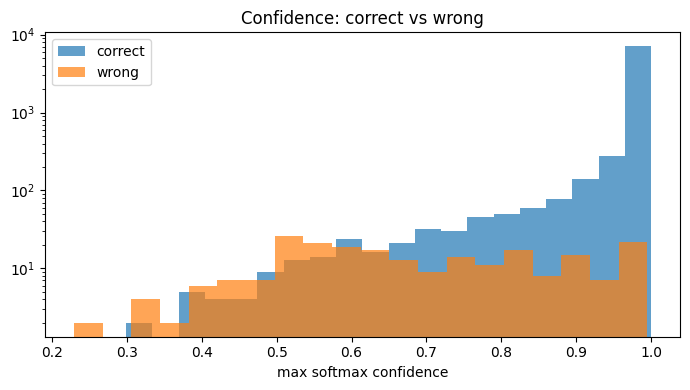

Mean confidence | correct: 0.982 | wrong: 0.683


In [22]:
conf = probs_eff.max(1); correct = (pred_eff == y_test)
plt.figure(figsize=(7, 4))
plt.hist(conf[correct], bins=20, alpha=0.7, label="correct")
plt.hist(conf[~correct], bins=20, alpha=0.7, label="wrong")
plt.yscale("log"); plt.xlabel("max softmax confidence"); plt.legend(); plt.title("Confidence: correct vs wrong")
plt.tight_layout(); plt.show()
print("Mean confidence | correct:", conf[correct].mean().round(3),
      "| wrong:", conf[~correct].mean().round(3) if (~correct).any() else "n/a")

## 12. Save the model

In [23]:
effnet.save("plant_disease_effnetb0.keras")
import json
with open("class_names.json", "w") as f:
    json.dump(class_names, f)
print("Saved model and class names.")

Saved model and class names.


## 13. Report notes (fill in with your results)

**Architecture:** Baseline = 4 x (Conv-BN-ReLU-MaxPool) + GAP + Dropout + Softmax. Main model = EfficientNetB0 (ImageNet) + GAP + Dropout(0.3) + Dense softmax. Augmentation layers are part of the model and active only in training.

**Training decisions:** stratified 70/15/15 split before augmentation; duplicates removed to prevent leakage; Adam; two-phase transfer learning (LR 1e-3 then 1e-5); BatchNorm frozen during fine-tuning; class weights for imbalance; EarlyStopping, ReduceLROnPlateau and ModelCheckpoint on validation loss; test set used once.

**Results:** insert the comparison table, confusion matrix, learning curves, Grad-CAM figures and field-image accuracy.

**Limitations:**
- Domain gap: PlantVillage images are lab-style with plain backgrounds, so accuracy typically drops on field photos (quantified in section 10).
- Class imbalance: mitigated with class weights, but rare classes still have noisier metrics.
- Calibration: softmax confidence can stay high on wrong predictions (section 11).
- Possible background shortcuts: check Grad-CAM for attention on the background instead of the lesion.
- Sensitive to lighting, blur and leaf orientation; a single leaf per image only; no severity estimation.

**Future work:** train with field-condition images, stronger augmentation, temperature scaling for calibration, test-time augmentation, an "unknown / not a leaf" class.

## Optional: Gradio demo

In [24]:
!pip install -q gradio
import gradio as gr

def predict_leaf(img):
    x = tf.image.resize(tf.convert_to_tensor(img, dtype=tf.float32), (IMG_SIZE, IMG_SIZE)).numpy()
    probs = effnet.predict(x[None, ...], verbose=0)[0]
    top = probs.argsort()[::-1][:3]
    return {class_names[i]: float(probs[i]) for i in top}

gr.Interface(fn=predict_leaf, inputs=gr.Image(), outputs=gr.Label(num_top_classes=3),
             title="Plant disease detector").launch(share=True)

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://9ec2c3724e05ef6dd0.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)
